In [2]:
from pathlib import Path

import sys
import json
import hashlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch

In [3]:
PROJECT_DIR = Path(r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca")

DATASET_DIR = (
    PROJECT_DIR / "dataset" / "raw" / "cassava_dataset"
)

REPORTS_DIR = PROJECT_DIR / "reports"

CONFIGS_DIR = PROJECT_DIR / "configs"

SPLITS_PATH = REPORTS_DIR / "dataset_splits.csv"

FEDERATED_SPLITS_PATH = (
    REPORTS_DIR / "federated_splits.csv"
)

PREPROCESSING_PATH = (
    CONFIGS_DIR / "preprocessing_config.json"
)

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(0, str(PROJECT_DIR))

In [4]:
with open(
    CONFIGS_DIR / "dataset_config.json",
    "r",
    encoding="utf-8"
) as f:

    config = json.load(f)


with open(
    CONFIGS_DIR / "dataloader_config.json",
    "r",
    encoding="utf-8"
) as f:

    dataloader_config = json.load(f)


SEED = config["seed"]

NUM_CLASSES = config["dataset_statistics"]["num_classes"]

N_SPLITS = config["cross_validation"]["n_splits"]

CLASS_MAPPING = config["class_mapping"]

BATCH_SIZE = dataloader_config["batch_size"]

NUM_WORKERS = dataloader_config["num_workers"]

print("Semilla:", SEED)
print("Clases:", NUM_CLASSES)
print("Folds:", N_SPLITS)
print("Batch size:", BATCH_SIZE)

Semilla: 42
Clases: 5
Folds: 3
Batch size: 32


In [5]:
NUM_SERVERS = 1

NUM_CLIENTS = 2

DISTRIBUTION_TYPE = "IID"

FEDERATED_ALGORITHM = "FedAvg"

print("Número de servidores:", NUM_SERVERS)

print("Número de clientes:", NUM_CLIENTS)

print("Tipo de distribución:", DISTRIBUTION_TYPE)

print("Algoritmo:", FEDERATED_ALGORITHM)

Número de servidores: 1
Número de clientes: 2
Tipo de distribución: IID
Algoritmo: FedAvg


In [6]:
df_splits = pd.read_csv(SPLITS_PATH)

df_development = df_splits[
    df_splits["split"] == "development"
].copy()

df_test = df_splits[
    df_splits["split"] == "test"
].copy()

print("Total de imágenes:", len(df_splits))

print("Imágenes disponibles para clientes:", len(df_development))

print("Imágenes reservadas para test:", len(df_test))

display(df_development.head())

Total de imágenes: 21397
Imágenes disponibles para clientes: 18187
Imágenes reservadas para test: 3210


,filename,filepath,class,extension,width,height,format,mode,size_bytes,sha256,status,error,split,fold
0,2422491518.jpg,mosaic_disease\2422491518.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,124540,568dbafb87aec5908d558598dd7391d0bd6c15e7fd33fd...,valid,NaN,development,3
1,2878596544.jpg,mosaic_disease\2878596544.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,143096,a24b7bc16ac427258d93de3bc06c78625e5eb632ba8f93...,valid,NaN,development,2
2,1696364421.jpg,green_mottle\1696364421.jpg,green_mottle,.jpg,800,600,JPEG,RGB,82996,5037e2d79f82f25519924a581be8cac219bef654cc8957...,valid,NaN,development,3
3,3806158675.jpg,mosaic_disease\3806158675.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,127459,25599e588ba4e49fd8bb6874db71e42da827bee10ba49e...,valid,NaN,development,3
4,1132695066.jpg,mosaic_disease\1132695066.jpg,mosaic_disease,.jpg,800,600,JPEG,RGB,110081,000e1d7184525f915868312102bc8f422fdd586594473c...,valid,NaN,development,2


In [7]:
assert df_splits["filepath"].is_unique

assert df_splits["sha256"].notna().all()

assert df_splits["sha256"].is_unique, (
    "Existen duplicados exactos pendientes de resolver."
)

assert set(df_development["fold"].unique()) == set(
    range(1, N_SPLITS + 1)
)

assert df_test["fold"].eq(-1).all()

print("Dataset preparado para la distribución federada.")

Dataset preparado para la distribución federada.


In [8]:
class_fold_counts = pd.crosstab(
    df_development["class"],
    df_development["fold"]
)

display(class_fold_counts)

if (class_fold_counts < NUM_CLIENTS).any().any():

    print(
        "Advertencia: algunas clases tienen menos imágenes "
        "por fold que clientes disponibles."
    )

else:

    print(
        "Hay suficientes imágenes por clase y fold "
        "para distribuir entre los clientes."
    )

fold,1,2,3
class,,,
bacterial_blight,308,308,308
brown_streak_disease,621,620,620
green_mottle,676,676,676
healthy,730,730,730
mosaic_disease,3728,3728,3728


Hay suficientes imágenes por clase y fold para distribuir entre los clientes.


In [9]:
def assign_iid_clients(
    dataframe,
    num_clients,
    seed
):

    if num_clients < 1:
        raise ValueError("Debe existir al menos un cliente.")

    rng = np.random.default_rng(seed)

    df_clients = dataframe.sort_values(
        "filepath"
    ).reset_index(drop=True).copy()

    df_clients["client_id"] = -1

    grouped = df_clients.groupby(
        ["class", "fold"],
        sort=True
    )

    for (class_name, fold), group in grouped:

        indices = group.index.to_numpy()

        shuffled_indices = rng.permutation(indices)

        partitions = np.array_split(
            shuffled_indices,
            num_clients
        )

        client_ids = rng.permutation(
            np.arange(1, num_clients + 1)
        )

        for client_id, partition in zip(
            client_ids,
            partitions
        ):

            df_clients.loc[
                partition,
                "client_id"
            ] = int(client_id)

    return df_clients

In [10]:
df_clients = assign_iid_clients(

    dataframe=df_development,

    num_clients=NUM_CLIENTS,

    seed=SEED

)

print("Imágenes distribuidas:", len(df_clients))

display(
    df_clients[
        ["filepath", "class", "fold", "client_id"]
    ].head(10)
)

Imágenes distribuidas: 18187


,filepath,class,fold,client_id
0,bacterial_blight\1000015157.jpg,bacterial_blight,2,2
1,bacterial_blight\1001320321.jpg,bacterial_blight,3,1
2,bacterial_blight\1003888281.jpg,bacterial_blight,2,1
3,bacterial_blight\1012426959.jpg,bacterial_blight,1,1
4,bacterial_blight\102039365.jpg,bacterial_blight,1,2
5,bacterial_blight\1021758544.jpg,bacterial_blight,1,1
6,bacterial_blight\1024089865.jpg,bacterial_blight,1,1
7,bacterial_blight\102485576.jpg,bacterial_blight,1,1
8,bacterial_blight\1026467332.jpg,bacterial_blight,2,1
9,bacterial_blight\1027796931.jpg,bacterial_blight,3,1


In [11]:
df_test["client_id"] = -1

df_federated = pd.concat(

    [df_clients, df_test],

    ignore_index=True

)

df_federated["client_id"] = (
    df_federated["client_id"].astype(int)
)

display(
    df_federated[
        [
            "filepath",
            "class",
            "split",
            "fold",
            "client_id"
        ]
    ].head(10)
)

,filepath,class,split,fold,client_id
0,bacterial_blight\1000015157.jpg,bacterial_blight,development,2,2
1,bacterial_blight\1001320321.jpg,bacterial_blight,development,3,1
2,bacterial_blight\1003888281.jpg,bacterial_blight,development,2,1
3,bacterial_blight\1012426959.jpg,bacterial_blight,development,1,1
4,bacterial_blight\102039365.jpg,bacterial_blight,development,1,2
5,bacterial_blight\1021758544.jpg,bacterial_blight,development,1,1
6,bacterial_blight\1024089865.jpg,bacterial_blight,development,1,1
7,bacterial_blight\102485576.jpg,bacterial_blight,development,1,1
8,bacterial_blight\1026467332.jpg,bacterial_blight,development,2,1
9,bacterial_blight\1027796931.jpg,bacterial_blight,development,3,1


In [12]:
client_distribution = (

    df_clients["client_id"]

    .value_counts()

    .sort_index()

    .rename("num_images")

    .reset_index()

)

display(client_distribution)

,client_id,num_images
0,1,9093
1,2,9094


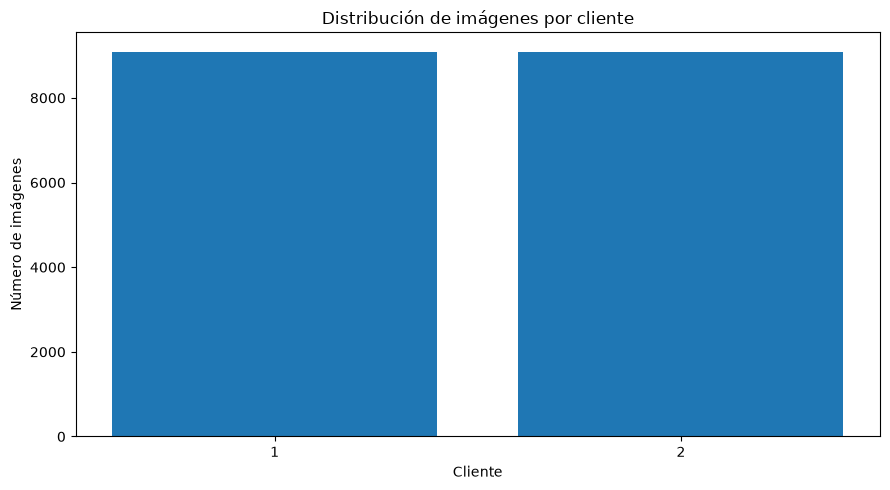

In [13]:
plt.figure(figsize=(9, 5))

plt.bar(

    client_distribution["client_id"].astype(str),

    client_distribution["num_images"]

)

plt.title("Distribución de imágenes por cliente")

plt.xlabel("Cliente")

plt.ylabel("Número de imágenes")

plt.tight_layout()

plt.savefig(

    REPORTS_DIR / "client_distribution.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

In [14]:
client_class_distribution = pd.crosstab(

    df_clients["client_id"],

    df_clients["class"]

)

display(client_class_distribution)

class,bacterial_blight,brown_streak_disease,green_mottle,healthy,mosaic_disease
client_id,,,,,
1,462,930,1014,1095,5592
2,462,931,1014,1095,5592


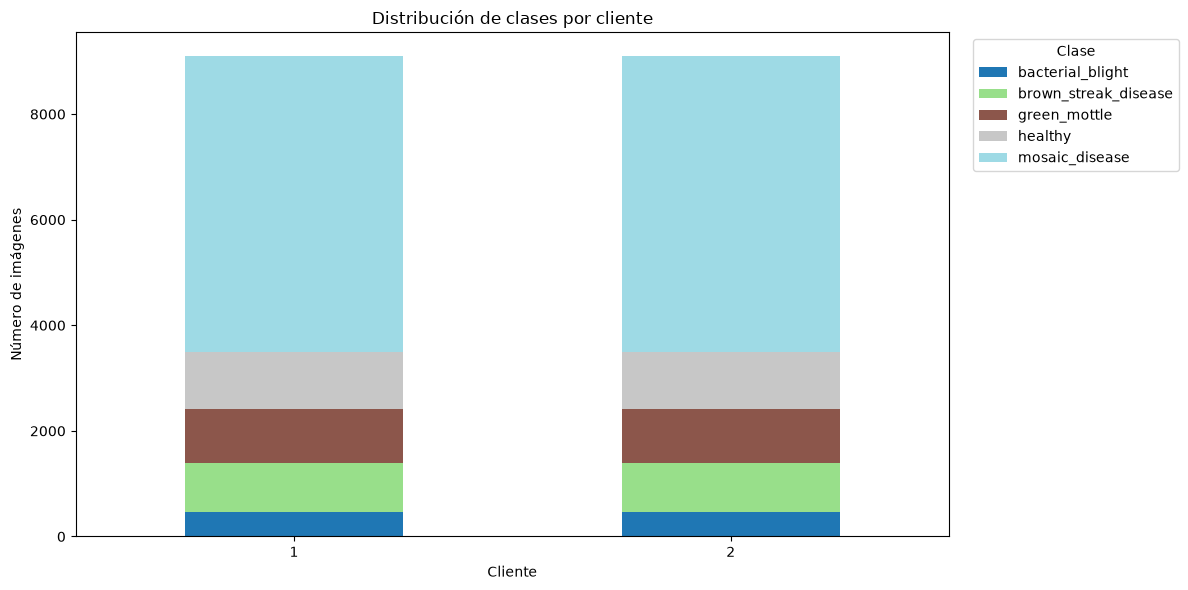

In [15]:
ax = client_class_distribution.plot(

    kind="bar",

    stacked=True,

    figsize=(12, 6),

    colormap="tab20"

)

ax.set_title("Distribución de clases por cliente")

ax.set_xlabel("Cliente")

ax.set_ylabel("Número de imágenes")

plt.xticks(rotation=0)

plt.legend(

    title="Clase",

    bbox_to_anchor=(1.02, 1),

    loc="upper left"

)

plt.tight_layout()

plt.savefig(

    REPORTS_DIR / "client_class_distribution.png",

    dpi=150,

    bbox_inches="tight"

)

plt.show()

In [16]:
client_class_percentages = (

    pd.crosstab(

        df_clients["client_id"],

        df_clients["class"],

        normalize="index"

    ) * 100

).round(2)

display(client_class_percentages)

class,bacterial_blight,brown_streak_disease,green_mottle,healthy,mosaic_disease
client_id,,,,,
1,5.08,10.23,11.15,12.04,61.50
2,5.08,10.24,11.15,12.04,61.49


In [17]:
client_fold_distribution = pd.crosstab(

    df_clients["client_id"],

    df_clients["fold"]

)

display(client_fold_distribution)

fold,1,2,3
client_id,,,
1,3031,3031,3031
2,3032,3031,3031


In [18]:
# No se perdieron ni agregaron imágenes
assert len(df_federated) == len(df_splits)

# Cada imagen aparece una sola vez
assert df_federated["filepath"].is_unique

assert df_federated["sha256"].is_unique

# Todos los clientes están disponibles
assert set(df_clients["client_id"].unique()) == set(
    range(1, NUM_CLIENTS + 1)
)

# Los clientes solo contienen imágenes de desarrollo
assert df_clients["split"].eq("development").all()

# Test no pertenece a ningún cliente
assert df_federated.loc[

    df_federated["split"] == "test",

    "client_id"

].eq(-1).all()

# Verificar que no se modificaron las asignaciones originales
original = df_splits.set_index(
    "filepath"
).sort_index()

federated = df_federated.set_index(
    "filepath"
).sort_index()

pd.testing.assert_frame_equal(

    original[["class", "split", "fold", "sha256"]],

    federated[["class", "split", "fold", "sha256"]]

)

print("Todas las verificaciones fueron superadas.")

Todas las verificaciones fueron superadas.


In [19]:
for client_a in range(1, NUM_CLIENTS + 1):

    hashes_a = set(

        df_clients.loc[

            df_clients["client_id"] == client_a,

            "sha256"

        ]

    )

    for client_b in range(
        client_a + 1,
        NUM_CLIENTS + 1
    ):

        hashes_b = set(

            df_clients.loc[

                df_clients["client_id"] == client_b,

                "sha256"

            ]

        )

        assert hashes_a.isdisjoint(hashes_b), (

            f"Solapamiento entre clientes "
            f"{client_a} y {client_b}"

        )

print("No existen imágenes idénticas compartidas entre clientes.")

No existen imágenes idénticas compartidas entre clientes.


In [20]:
df_clients_check = assign_iid_clients(

    dataframe=df_development,

    num_clients=NUM_CLIENTS,

    seed=SEED

)

pd.testing.assert_frame_equal(

    df_clients[["filepath", "client_id"]],

    df_clients_check[["filepath", "client_id"]]

)

print("La distribución federada es reproducible.")

La distribución federada es reproducible.


In [21]:
df_federated.to_csv(

    FEDERATED_SPLITS_PATH,

    index=False,

    encoding="utf-8-sig"

)

client_distribution.to_csv(

    REPORTS_DIR / "client_distribution.csv",

    index=False,

    encoding="utf-8-sig"

)

client_class_distribution.to_csv(

    REPORTS_DIR / "client_class_distribution.csv",

    encoding="utf-8-sig"

)

client_class_percentages.to_csv(

    REPORTS_DIR / "client_class_percentages.csv",

    encoding="utf-8-sig"

)

client_fold_distribution.to_csv(

    REPORTS_DIR / "client_fold_distribution.csv",

    encoding="utf-8-sig"

)

print("Distribución federada y reportes guardados.")

Distribución federada y reportes guardados.


In [22]:
from src.preprocessing import build_transforms

from src.federated_data import (

    create_client_loader,

    create_global_val_loader

)

In [23]:
train_transform, eval_transform = build_transforms(

    PREPROCESSING_PATH

)

torch.manual_seed(SEED)

np.random.seed(SEED)

print("Transformaciones recuperadas.")

Transformaciones recuperadas.


In [24]:
CURRENT_FOLD = 1

client_loaders = {}

for client_id in range(1, NUM_CLIENTS + 1):

    client_loaders[client_id] = create_client_loader(

        df_federated=df_federated,

        dataset_dir=DATASET_DIR,

        class_mapping=CLASS_MAPPING,

        train_transform=train_transform,

        client_id=client_id,

        fold=CURRENT_FOLD,

        batch_size=BATCH_SIZE,

        num_workers=NUM_WORKERS,

        seed=SEED

    )

    print(

        f"Cliente {client_id}: "

        f"{len(client_loaders[client_id].dataset)} imágenes, "

        f"{len(client_loaders[client_id])} batches"

    )

Cliente 1: 6062 imágenes, 190 batches
Cliente 2: 6062 imágenes, 190 batches


In [25]:
global_val_loader = create_global_val_loader(

    df_federated=df_federated,

    dataset_dir=DATASET_DIR,

    class_mapping=CLASS_MAPPING,

    eval_transform=eval_transform,

    fold=CURRENT_FOLD,

    batch_size=BATCH_SIZE,

    num_workers=NUM_WORKERS,

    seed=SEED

)

print(

    "Imágenes de validación global:",

    len(global_val_loader.dataset)

)

Imágenes de validación global: 6063


In [26]:
with open(

    PREPROCESSING_PATH,

    "r",

    encoding="utf-8"

) as f:

    preprocessing_config = json.load(f)


expected_shape = (

    preprocessing_config["num_channels"],

    *preprocessing_config["image_size"]

)

for client_id, loader in client_loaders.items():

    images, labels = next(iter(loader))

    assert tuple(images.shape[1:]) == expected_shape

    assert images.dtype == torch.float32

    assert labels.dtype == torch.long

    assert len(images) == len(labels)

    assert labels.min().item() >= 0

    assert labels.max().item() < NUM_CLASSES

    assert torch.isfinite(images).all()

    print(

        f"Cliente {client_id}: "

        f"Imágenes {images.shape}, "

        f"Etiquetas {labels.shape}"

    )

Cliente 1: Imágenes torch.Size([32, 3, 224, 224]), Etiquetas torch.Size([32])
Cliente 2: Imágenes torch.Size([32, 3, 224, 224]), Etiquetas torch.Size([32])


In [27]:
federated_records = []

test_hashes = set(

    df_federated.loc[

        df_federated["split"] == "test",

        "sha256"

    ]

)

for fold in range(1, N_SPLITS + 1):

    val_hashes = set(

        df_federated.loc[

            (df_federated["split"] == "development") &

            (df_federated["fold"] == fold),

            "sha256"

        ]

    )

    all_train_hashes = set()

    for client_id in range(1, NUM_CLIENTS + 1):

        loader = create_client_loader(

            df_federated=df_federated,

            dataset_dir=DATASET_DIR,

            class_mapping=CLASS_MAPPING,

            train_transform=train_transform,

            client_id=client_id,

            fold=fold,

            batch_size=BATCH_SIZE,

            num_workers=NUM_WORKERS,

            seed=SEED

        )

        client_df = loader.dataset.dataframe

        client_hashes = set(client_df["sha256"])

        assert client_df["client_id"].eq(client_id).all()

        assert client_df["split"].eq("development").all()

        assert client_df["fold"].ne(fold).all()

        assert client_hashes.isdisjoint(val_hashes)

        assert client_hashes.isdisjoint(test_hashes)

        assert client_hashes.isdisjoint(all_train_hashes)

        all_train_hashes.update(client_hashes)

        federated_records.append({

            "fold": fold,

            "client_id": client_id,

            "train_images": len(client_df),

            "train_batches": len(loader),

            "classes_present": client_df["class"].nunique()

        })

    expected_train_hashes = set(

        df_federated.loc[

            (df_federated["split"] == "development") &

            (df_federated["fold"] != fold),

            "sha256"

        ]

    )

    assert all_train_hashes == expected_train_hashes

    assert val_hashes.isdisjoint(test_hashes)

    print(f"Fold {fold}: verificación correcta.")


df_federated_summary = pd.DataFrame(
    federated_records
)

display(df_federated_summary)

df_federated_summary.to_csv(

    REPORTS_DIR / "federated_dataloader_summary.csv",

    index=False,

    encoding="utf-8-sig"

)

Fold 1: verificación correcta.
Fold 2: verificación correcta.
Fold 3: verificación correcta.


,fold,client_id,train_images,train_batches,classes_present
0,1,1,6062,190,5
1,1,2,6062,190,5
2,2,1,6062,190,5
3,2,2,6063,190,5
4,3,1,6062,190,5
5,3,2,6063,190,5


In [28]:
assert len(df_federated_summary) == (
    NUM_CLIENTS * N_SPLITS
)

print(
    "Combinaciones cliente-fold verificadas:",
    len(df_federated_summary)
)

Combinaciones cliente-fold verificadas: 6


In [29]:
federated_config = {

    "algorithm": FEDERATED_ALGORITHM,

    "simulation": True,

    "num_servers": NUM_SERVERS,

    "num_clients": NUM_CLIENTS,

    "architecture": "centralized_federated",

    "distribution": {

        "type": DISTRIBUTION_TYPE,

        "method": "stratified_class_fold",

        "fixed_client_assignment": True,

        "seed": SEED

    },

    "cross_validation": {

        "n_splits": N_SPLITS,

        "validation": "global"

    },

    "test": {

        "excluded_from_clients": True,

        "client_id": -1

    },

    "statistics": {

        "total_images": len(df_federated),

        "federated_images": len(df_clients),

        "test_images": len(df_test),

        "num_classes": NUM_CLASSES

    },

    "files": {

        "original_splits": "reports/dataset_splits.csv",

        "federated_splits": "reports/federated_splits.csv"

    }

}

FEDERATED_CONFIG_PATH = (

    CONFIGS_DIR / "federated_config.json"

)

with open(

    FEDERATED_CONFIG_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        federated_config,

        f,

        indent=4

    )

print("Configuración federada guardada.")

Configuración federada guardada.


In [30]:
def calculate_sha256(filepath):

    sha256 = hashlib.sha256()

    with open(filepath, "rb") as f:

        for block in iter(

            lambda: f.read(1024 * 1024),

            b""

        ):

            sha256.update(block)

    return sha256.hexdigest()


files_to_verify = [

    SPLITS_PATH,

    FEDERATED_SPLITS_PATH,

    FEDERATED_CONFIG_PATH

]

integrity_records = []

for filepath in files_to_verify:

    integrity_records.append({

        "file": filepath.relative_to(
            PROJECT_DIR
        ).as_posix(),

        "sha256": calculate_sha256(filepath)

    })


df_federated_integrity = pd.DataFrame(

    integrity_records

)

df_federated_integrity.to_csv(

    REPORTS_DIR / "federated_file_integrity.csv",

    index=False,

    encoding="utf-8-sig"

)

display(df_federated_integrity)

,file,sha256
0,reports/dataset_splits.csv,21d5f7c006c38fecead271b56c0bf68e4938cdde24deee...
1,reports/federated_splits.csv,419aca652118f42c60cd2ddf7774f0318a3fa9efef9632...
2,configs/federated_config.json,46ebe6af9d6ff48623b78ac227a81db2b305c0728e4d91...
